# A GNN ranker over the capstone KG's design layer

**CS 5588 Challenge 3, GNN stage.** The class notebook (`graphrag_neo4j_gnn.ipynb`) trains a GNN on a synthetic paper
graph. This one runs the same recipe on our own graph and asks the lecture's question (slide 20): does GNN scoring rank
the evidence better than text similarity alone, or do rules and text already suffice?

- **Input:** `design-graph.json`, written by `kg/export_design.py` (read-only). The design layer's nodes and edges, plus
  five questions whose **gold** sets are the design-node keys that `kg/graphrag.py`'s reviewed Cypher retrievals return.
- **No Neo4j here.** Like the class notebook, everything runs in memory, on the class notebook's `.venv`.
- **Model:** a homogeneous two-layer GraphSAGE trained by link prediction. Not `to_hetero`, because the design layer has
  31 relationship types over 146 nodes, and most types would train their own weights on a handful of edges.

Set `GNN_FIG_DIR` to save the figures as PNGs.

In [1]:
import json, os, random, math
from collections import Counter
from pathlib import Path

import numpy as np
import networkx as nx
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch_geometric.nn import SAGEConv

SEED = 7
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG_DIR = os.environ.get("GNN_FIG_DIR")
def save(fig, name):
    if FIG_DIR:
        Path(FIG_DIR).mkdir(parents=True, exist_ok=True); fig.savefig(Path(FIG_DIR) / name, bbox_inches="tight", dpi=160)

D = json.loads(Path("design-graph.json").read_text(encoding="utf-8"))
nodes = {n["key"]: n for n in D["nodes"]}
keys = list(nodes)
idx = {k: i for i, k in enumerate(keys)}
G = nx.MultiDiGraph()
for n in D["nodes"]: G.add_node(n["key"], label=n["label"])
for e in D["edges"]: G.add_edge(e["source"], e["target"], rel=e["type"])
U = nx.Graph(G)   # undirected, one edge per pair: message passing runs both ways
print(G, "|", len(Counter(e["type"] for e in D["edges"])), "relationship types |", U.number_of_edges(), "undirected pairs")
print("edges per relationship type:", sorted(Counter(e["type"] for e in D["edges"]).values()))

/home/daniel/code/graphrag-neo4j-gnn/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MultiDiGraph with 146 nodes and 451 edges | 31 relationship types | 451 undirected pairs
edges per relationship type: [1, 1, 1, 1, 1, 1, 2, 2, 2, 3, 3, 4, 4, 4, 5, 5, 7, 10, 12, 12, 13, 14, 14, 15, 17, 42, 42, 42, 43, 56, 72]


/home/daniel/code/graphrag-neo4j-gnn/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 1. One GraphSAGE layer by hand

Before training anything: one mean-aggregator layer on `find-width` and its six real neighbours, with toy 3-d features
`[fail, plan, ctx]` and toy weights (the same numbers as the explainer page). The hand computation has to match PyG's
`SAGEConv` loaded with the same weights.

`h′ = W_self · h_v + W_neigh · mean(h_u for u in N(v)) + b`

In [2]:
nbrs = sorted(U.neighbors("find-width"))
print("neighbours of find-width in the graph:", nbrs)
toy = {"find-width": [0.6, 0.0, 0.8], "sg-rev1": [0.0, 1.0, 0.6], "rev3": [0.2, 1.0, 0.1], "env-v-flap-v": [0.0, 0.2, 1.0],
       "outcome-1": [1.0, 0.0, 0.0], "outcome-3": [1.0, 0.1, 0.0], "outcome-4": [0.9, 0.0, 0.1]}
assert set(nbrs) == set(toy) - {"find-width"}, "the toy example no longer matches the graph"
order = ["find-width"] + nbrs
Xt = np.array([toy[k] for k in order], dtype=np.float32)
W_self = np.array([[0.5, -0.3, 0.4], [-0.2, 0.6, 0.3]], dtype=np.float32)
W_neigh = np.array([[0.7, 0.1, -0.4], [0.2, 0.5, 0.6]], dtype=np.float32)
b = np.array([0.0, -0.1], dtype=np.float32)

for aggr in ("mean", "max"):
    m = Xt[1:].mean(0) if aggr == "mean" else Xt[1:].max(0)            # 1. aggregate the neighbours
    by_hand = W_self @ Xt[0] + W_neigh @ m + b                            # 2. combine with the node itself
    conv = SAGEConv(3, 2, aggr=aggr)                                      # lin_l = W_neigh (+ bias), lin_r = W_self
    with torch.no_grad():
        conv.lin_l.weight.copy_(torch.tensor(W_neigh)); conv.lin_l.bias.copy_(torch.tensor(b))
        conv.lin_r.weight.copy_(torch.tensor(W_self))
        ei = torch.tensor([list(range(1, len(order))), [0] * (len(order) - 1)])   # every neighbour -> find-width
        pyg = conv(torch.tensor(Xt), ei)[0].numpy()
    print(f"{aggr:4s}  m = {m.round(3)}  by hand = {by_hand.round(3)}  SAGEConv = {pyg.round(3)}  match: {np.allclose(by_hand, pyg, atol=1e-6)}")

neighbours of find-width in the graph: ['env-v-flap-v', 'outcome-1', 'outcome-3', 'outcome-4', 'rev3', 'sg-rev1']
mean  m = [0.517 0.383 0.3  ]  by hand = [0.9   0.495]  SAGEConv = [0.9   0.495]  match: True
max   m = [1. 1. 1.]  by hand = [1.02 1.32]  SAGEConv = [1.02 1.32]  match: True


## 2. Text features

Each node's text (its label plus every string property: names, statements, definitions, notes) goes through TF-IDF and
SVD to a 32-d vector, as in the class notebook. The question is embedded the same way, which is what the seeding step uses.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline

texts = [f"{nodes[k]['label']} {k.replace('-', ' ')} {nodes[k]['text']}" for k in keys]
embedder = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True), TruncatedSVD(32, random_state=SEED)).fit(texts)
def embed(ts):
    v = embedder.transform(ts).astype(np.float32)
    return v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-9)
X = embed(texts)
print("features", X.shape)

features (146, 32)


## 3. Train GraphSAGE by link prediction

No labels are needed: real edges should score high (`σ(h_a · h_b)`), random non-edges low. 15% of the undirected
pairs are held out to measure that, and they are left out of the training graph's message passing too.

held-out link prediction AUC = 0.73  (67 held-out pairs)


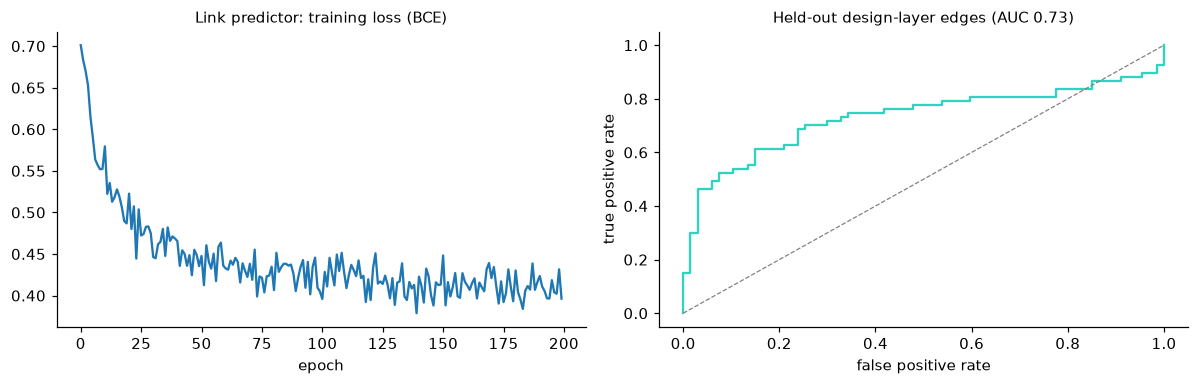

In [4]:
pairs = [(idx[a], idx[b]) for a, b in U.edges()]
perm = np.random.permutation(len(pairs))
n_test = int(0.15 * len(pairs))
test_pairs = [pairs[i] for i in perm[:n_test]]; train_pairs = [pairs[i] for i in perm[n_test:]]
all_pairs = set(pairs) | {(b, a) for a, b in pairs}

def both_ways(ps):
    a = torch.tensor(ps).t()
    return torch.cat([a, a.flip(0)], 1)

def negatives(n):
    out = []
    while len(out) < n:
        a, b = random.randrange(len(keys)), random.randrange(len(keys))
        if a != b and (a, b) not in all_pairs: out.append((a, b))
    return torch.tensor(out).t()

class SAGE(torch.nn.Module):
    def __init__(self, d_in, hidden=64, out=32):
        super().__init__()
        self.conv1 = SAGEConv(d_in, hidden); self.conv2 = SAGEConv(hidden, out)
    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, 0.2, self.training)
        return self.conv2(x, edge_index)

x = torch.tensor(X)
train_ei, full_ei = both_ways(train_pairs), both_ways(pairs)
train_pos = torch.tensor(train_pairs).t()
model = SAGE(X.shape[1]); opt = torch.optim.Adam(model.parameters(), lr=0.01)
score = lambda h, e: (h[e[0]] * h[e[1]]).sum(-1)
hist = []
for epoch in range(200):
    model.train(); opt.zero_grad()
    h = model(x, train_ei)
    neg = negatives(train_pos.size(1))
    logits = torch.cat([score(h, train_pos), score(h, neg)])
    labels = torch.cat([torch.ones(train_pos.size(1)), torch.zeros(neg.size(1))])
    loss = F.binary_cross_entropy_with_logits(logits, labels); loss.backward(); opt.step(); hist.append(loss.item())

from sklearn.metrics import roc_auc_score, roc_curve
model.eval()
with torch.no_grad():
    h = model(x, train_ei)
    tp = torch.tensor(test_pairs).t(); tn = negatives(tp.size(1))
    y_score = torch.sigmoid(torch.cat([score(h, tp), score(h, tn)])).numpy()
y_true = np.r_[np.ones(tp.size(1)), np.zeros(tn.size(1))]
auc = roc_auc_score(y_true, y_score)
print(f"held-out link prediction AUC = {auc:.2f}  ({tp.size(1)} held-out pairs)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(hist); ax[0].set_xlabel("epoch"); ax[0].set_title("Link predictor: training loss (BCE)", fontsize=10)
fpr, tpr, _ = roc_curve(y_true, y_score)
ax[1].plot(fpr, tpr, color="#2DD4BF"); ax[1].plot([0, 1], [0, 1], "--", color="gray", lw=0.8)
ax[1].set_xlabel("false positive rate"); ax[1].set_ylabel("true positive rate")
ax[1].set_title(f"Held-out design-layer edges (AUC {auc:.2f})", fontsize=10)
plt.tight_layout(); save(fig, "gnn-training.png"); plt.show()

with torch.no_grad():
    H = model(x, full_ei)   # ranking embeds with the full graph, as the class notebook does (see the caveat in 5)

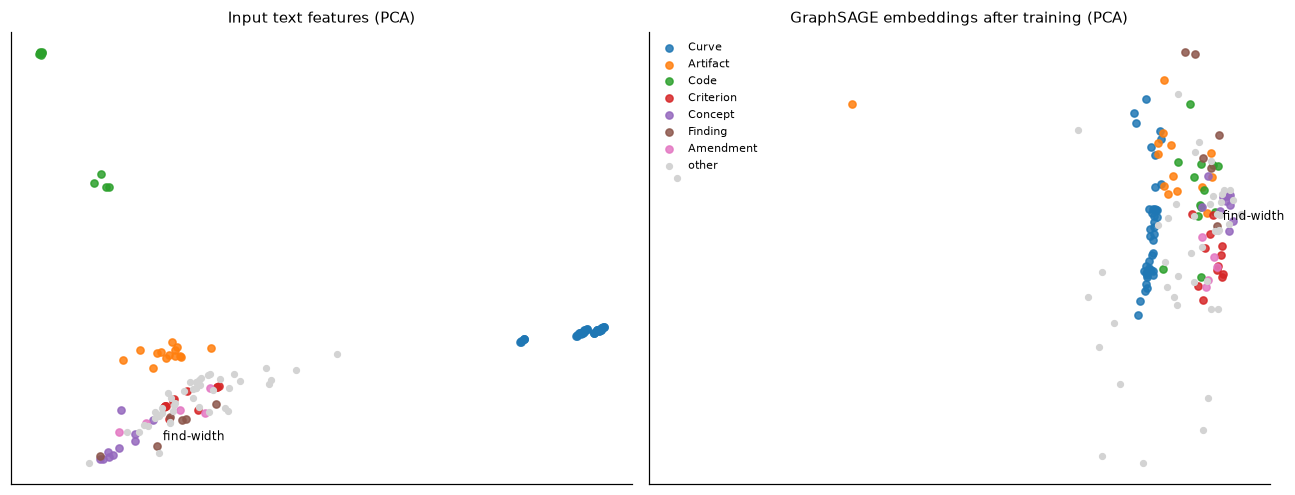

In [5]:
from sklearn.decomposition import PCA
labels_ = [nodes[k]["label"] for k in keys]
top = [l for l, _ in Counter(labels_).most_common(7)]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, M, title in ((ax[0], X, "Input text features (PCA)"), (ax[1], H.numpy(), "GraphSAGE embeddings after training (PCA)")):
    xy = PCA(2, random_state=SEED).fit_transform(M)
    for l in top:
        m = np.array([y == l for y in labels_]); a.scatter(xy[m, 0], xy[m, 1], s=22, label=l, alpha=0.85)
    m = np.array([y not in top for y in labels_]); a.scatter(xy[m, 0], xy[m, 1], s=14, c="lightgray", label="other")
    i = idx["find-width"]; a.annotate("find-width", xy[i], fontsize=8, xytext=(4, 4), textcoords="offset points")
    a.set_title(title, fontsize=10); a.set_xticks([]); a.set_yticks([])
ax[1].legend(fontsize=7, frameon=False, loc="best")
plt.tight_layout(); save(fig, "gnn-embeddings.png"); plt.show()

## 4. Three rankers, scored against the reviewed Cypher

The same seed → expand → score loop as section 9 of the class notebook:

1. **Vector only:** every node, by cosine similarity to the question.
2. **Graph expansion:** the top-3 vector seeds plus their 1-hop neighbours, ordered by vector similarity.
3. **Graph + GNN:** the same candidates, ordered by the link predictor: the mean of `σ(h_c · h_s)` over the seeds `s ≠ c`.

**Gold** is what `kg/graphrag.py`'s reviewed retrieval for that question returns. The score is **hits@5 out of the
possible**, `|top-5 ∩ gold| / min(5, |gold|)`, so a question with one gold node and one with seventeen are on the same
scale.

In [6]:
tfidf = embedder[0]                      # the pipeline's fitted TF-IDF step, for the raw-feature variant in 4b
X_raw = tfidf.transform(texts)

def rankers(question, features="svd", k_seeds=3, hops=1):
    "Headline settings are the class notebook's: SVD features, 3 seeds, 1 hop. Section 4b varies them."
    if features == "svd":
        sim = X @ embed([question])[0]
    else:
        sim = (X_raw @ tfidf.transform([question]).T).toarray().ravel()
    vec_only = [keys[i] for i in np.argsort(-sim)]
    seeds = vec_only[:k_seeds]
    cands, frontier = set(seeds), set(seeds)
    for _ in range(hops):
        frontier = {n for s in frontier for n in U.neighbors(s)} - cands
        cands |= frontier
    graph_vec = sorted(cands, key=lambda c: -sim[idx[c]])
    def gnn(c):
        others = [s for s in seeds if s != c]
        return float(np.mean([torch.sigmoid(H[idx[c]] @ H[idx[s]]).item() for s in others]))
    graph_gnn = sorted(cands, key=lambda c: -gnn(c))
    return seeds, {"vector only": vec_only, "graph expansion": graph_vec, "graph + GNN": graph_gnn}

K = 5
rows = []
for qq in D["questions"]:
    gold = set(qq["gold"])
    seeds, R = rankers(qq["question"])
    row = {"question": qq["question"], "retrieval": qq["retrieval"], "gold": len(gold), "seeds": seeds}
    for name, ranked in R.items():
        row[name] = len(set(ranked[:K]) & gold) / min(K, len(gold))
        row[name + " top5"] = ranked[:K]
    if "find-width" in gold:
        row["find-width rank"] = {name: (ranked.index("find-width") + 1 if "find-width" in ranked else None) for name, ranked in R.items()}
    rows.append(row)

names = ["vector only", "graph expansion", "graph + GNN"]
print(f"{'retrieval':22s} {'gold':>4s}  " + "  ".join(f"{n:>15s}" for n in names))
for r in rows:
    print(f"{r['retrieval']:22s} {r['gold']:4d}  " + "  ".join(f"{r[n]:15.2f}" for n in names))
print(f"{'mean':22s} {'':4s}  " + "  ".join(f"{np.mean([r[n] for r in rows]):15.2f}" for n in names))
for r in rows:
    print(f"\n{r['retrieval']}: seeds {r['seeds']}")
    for n in names: print(f"   {n:16s} top 5: {r[n + ' top5']}")
    if "find-width rank" in r: print("   find-width rank:", r["find-width rank"], "(None = not a candidate)")

retrieval              gold      vector only  graph expansion      graph + GNN
concept                   2             0.50             0.00             0.00
criterion_provenance      7             0.00             0.00             0.00
why_failed               17             0.00             0.00             0.00
word_axis                 8             0.00             0.00             0.00
registered_not_run        1             0.00             0.00             0.00
mean                                    0.10             0.00             0.00

concept: seeds ['env-flap', 'env-flap-v', 'env-v-flap']
   vector only      top 5: ['env-flap', 'env-flap-v', 'env-v-flap', 'env-v-flap-v', 'con-flap']
   graph expansion  top 5: ['env-flap', 'env-flap-v', 'env-v-flap', 'rev1', 'rev2']
   graph + GNN      top 5: ['sg-rev1', 'env-flap-v', 'env-v-flap', 'rev3', 'rev1']

criterion_provenance: seeds ['con-neutralization', 'con-surface', 'con-phone']
   vector only      top 5: ['con-neutralization

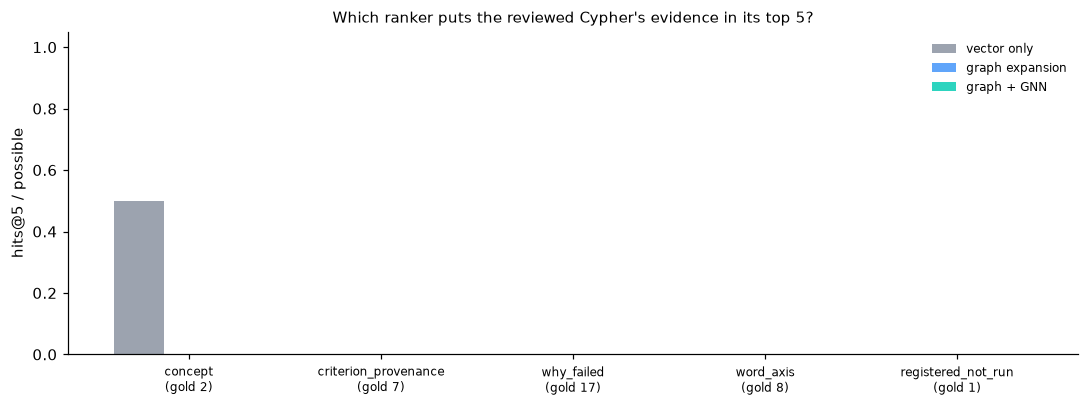

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.8))
w = 0.26; xs = np.arange(len(rows))
for j, (n, c) in enumerate(zip(names, ["#9CA3AF", "#60A5FA", "#2DD4BF"])):
    ax.bar(xs + (j - 1) * w, [r[n] for r in rows], w, label=n, color=c)
ax.set_xticks(xs, [f"{r['retrieval']}\n(gold {r['gold']})" for r in rows], fontsize=8)
ax.set_ylim(0, 1.05); ax.set_ylabel(f"hits@{K} / possible")
ax.set_title("Which ranker puts the reviewed Cypher's evidence in its top 5?", fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); save(fig, "gnn-rankers.png"); plt.show()

### 4b. Sensitivity: is the result an artifact of the settings?

The headline settings above were fixed before running (the class notebook's). Here one choice at a time is varied:
SVD vs. raw TF-IDF features, 3 vs. 5 seeds, 1 vs. 2 hops. All eight are shown. **Gold coverage** is the share of a
question's gold set that is among the candidates at all, the ceiling for both graph rankers. Five questions and eight
settings make this a pattern to look at, not a result to pick from.

setting                      vector only graph expansion     graph + GNN   gold coverage per question   mean candidates


svd, 3 seeds, 1 hop                 0.10            0.00            0.00   0.00 0.00 0.06 0.00 1.00       14
svd, 3 seeds, 2 hops                0.10            0.00            0.00   0.00 0.43 0.12 0.25 1.00       55
svd, 5 seeds, 1 hop                 0.10            0.10            0.00   1.00 0.00 0.06 0.00 1.00       18
svd, 5 seeds, 2 hops                0.10            0.10            0.00   1.00 0.43 0.18 0.25 1.00       59
raw, 3 seeds, 1 hop                 0.00            0.10            0.10   0.50 0.00 0.00 0.00 0.00       13
raw, 3 seeds, 2 hops                0.00            0.10            0.04   1.00 0.57 0.18 1.00 1.00       71
raw, 5 seeds, 1 hop                 0.00            0.00            0.32   1.00 0.14 0.35 0.00 1.00       26
raw, 5 seeds, 2 hops                0.00            0.00            0.22   1.00 0.71 0.82 1.00 1.00      110


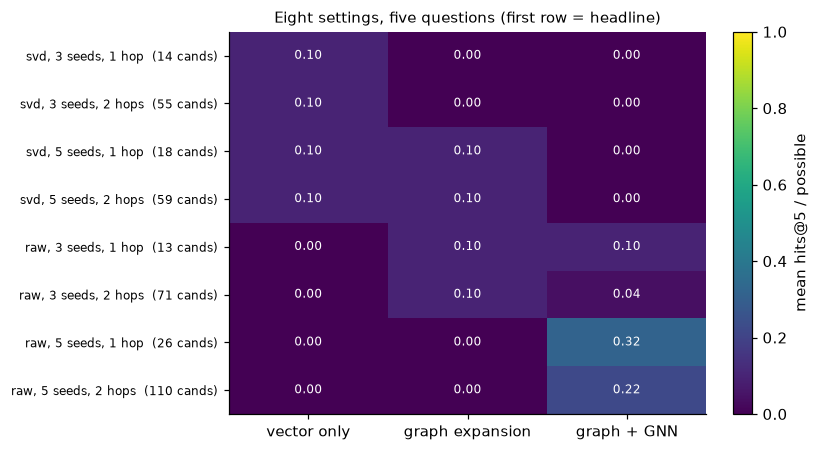

In [8]:
def hits(ranked, gold): return len(set(ranked[:K]) & gold) / min(K, len(gold))
grid = []
for features in ("svd", "raw"):
    for k_seeds in (3, 5):
        for hops in (1, 2):
            res, cov, ncand = [], [], []
            for qq in D["questions"]:
                gold = set(qq["gold"])
                seeds, R = rankers(qq["question"], features, k_seeds, hops)
                res.append([hits(R[n], gold) for n in names])
                cov.append(len(set(R["graph expansion"]) & gold) / len(gold)); ncand.append(len(R["graph expansion"]))
            grid.append((f"{features}, {k_seeds} seeds, {hops} hop{'s' if hops > 1 else ''}", np.mean(res, 0), cov, np.mean(ncand)))

print(f"{'setting':24s} " + " ".join(f"{n:>15s}" for n in names) + "   gold coverage per question   mean candidates")
for label, m, cov, nc in grid:
    print(f"{label:24s} " + " ".join(f"{v:15.2f}" for v in m) + "   " + " ".join(f"{c:.2f}" for c in cov) + f"   {nc:6.0f}")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
M = np.array([m for _, m, _, _ in grid])
im = ax.imshow(M, cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(3), names); ax.set_yticks(range(len(grid)), [f"{l}  ({nc:.0f} cands)" for l, _, _, nc in grid], fontsize=8)
for i in range(M.shape[0]):
    for j in range(M.shape[1]): ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if M[i, j] < 0.5 else "black")
plt.colorbar(im, ax=ax, fraction=0.04, label=f"mean hits@{K} / possible")
ax.set_title("Eight settings, five questions (first row = headline)", fontsize=10)
plt.tight_layout(); save(fig, "gnn-sensitivity.png"); plt.show()

## 5. Reading it

- **Text seeding is where it fails.** The questions' words ("why did the pilot fail", "criterion 2") aren't the words
  on the evidence nodes, so the seeds land on Concept nodes and the gold set is mostly not among the candidates. A GNN
  can only reorder candidates it is given. The reviewed router closes that gap differently: the LLM maps the question
  to one of five reviewed queries.
- **Five questions** are anecdotes, not a benchmark; read each row, not the mean.
- **Not question-disjoint**, as in the class notebook: the GNN was trained on the full graph, including the edges that
  connect each question's gold nodes, so its column is optimistic. The fix is to hold out each question's gold edges
  before training.
- **The comparison that matters is the reviewed Cypher itself.** It returns the gold set by construction, so it scores
  1.0 on every row. The rankers are what we'd need if the questions weren't routable to a reviewed query.